In [1]:
from pytem import TEM
from pygimli.viewer.mpl.overlayimage import underlayBKGMap

The instance is instantiated through the data file name. Instead of the USF files, we chose the xyz data files as it includes all soundings in one go. Whereas the data are in the xyz file, a gex file is exported containing the geometry of the loops, the time gates and the current waveform. If a file with the same name like the xyz file but the ending gex is found, it is read by default. Alternatively, you can specify this file explicitly by `cfg=`.

In [2]:
tem = TEM("sTEM.xyz")
print(tem)

TEM profile with 15 soundings
29 times (1.232756e-05-0.002356259)


The file contains 104 soundings with 28 time gates.
In the file, there are also the GPS positions that can be shown:

22/10/26 - 15:03:08 - pyGIMLi - INFO - Retrieving file from geodatenzentrum.de using URL: https://sgx.geodatenzentrum.de/wms_basemapde?service=wms&version=1.3.0&request=GetMap&Layers=de_basemapde_web_raster_farbe&STYLES=default&CRS=EPSG:25833&bbox=319917,5589470,322190,5591737&width=2500&Height=2493&Format=image/png


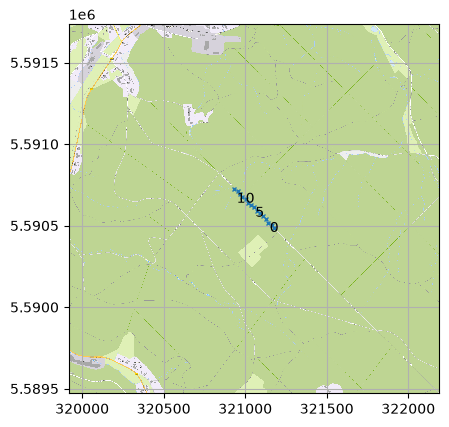

In [3]:
ax = tem.showPositions()
xl = ax.get_xlim()
yl = ax.get_ylim()
pad = 1000
ax.set_xlim(xl[0] - pad, xl[1] + pad)
ax.set_ylim(yl[0] - pad, yl[1] + pad)
underlayBKGMap(ax, utmzone=33)

In [4]:
# tem.filter(nmin=1)
# print(tem)

We can show all sounding by

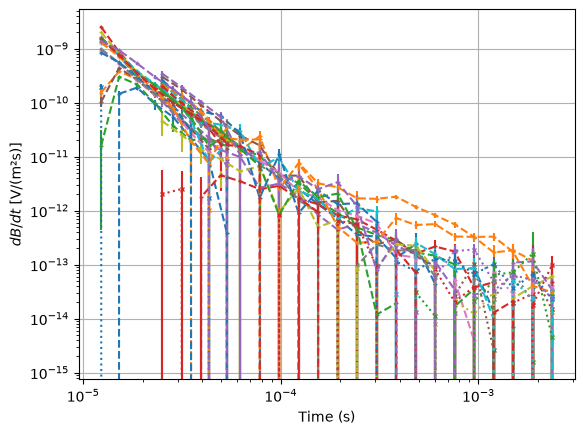

In [5]:
tem.showSoundings();

or a single sounding by

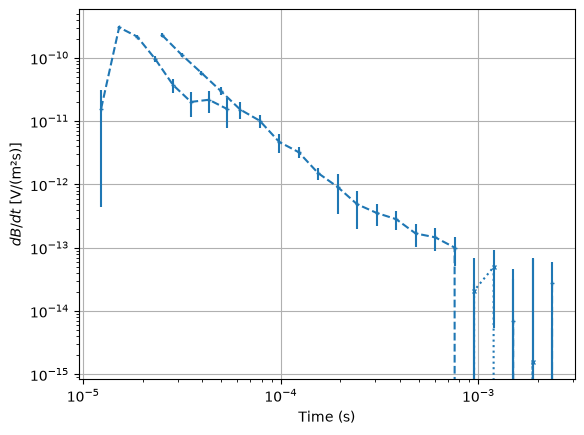

In [6]:
tem.showSounding(2);

or, transferred to apparent resistivity

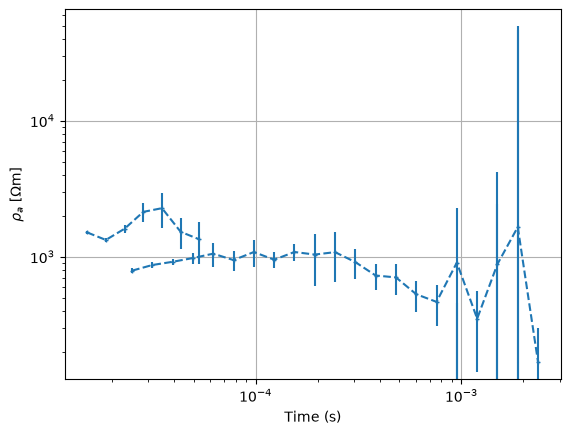

In [7]:
tem.showSounding(n=2, rhoa=True);

To view all data, we can use `showRhoa()`

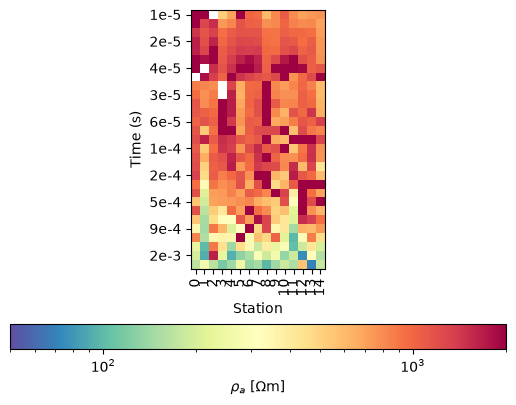

In [8]:
tem.showRhoa(rmin=50, rmax=2000);

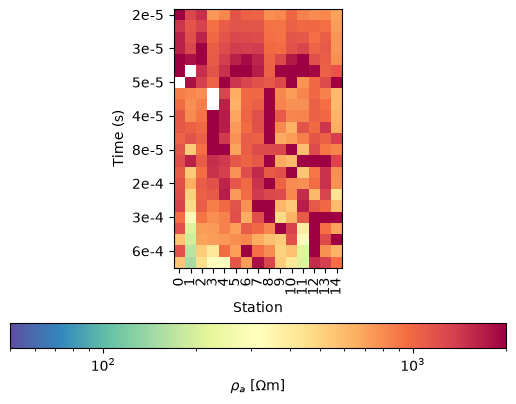

In [9]:
tem.filter(tmin=1.5e-5, tmax=8e-4)#n=[21])
tem.showRhoa(rmin=50, rmax=2000);

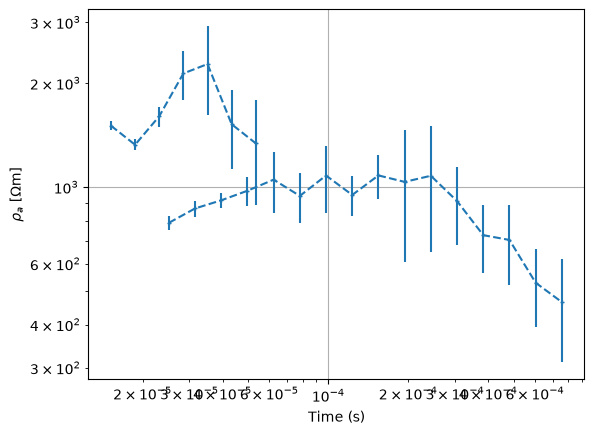

In [10]:
tem.showSounding(n=2, rhoa=True);

22/10/26 - 15:06:26 - pyGIMLi - INFO - Starting inversion.
22/10/26 - 15:06:26 - pyGIMLi - INFO - fop: <pytem.temmodelling.TEMRhoModellingDualMode object at 0x0000025EEA1A66B0>
22/10/26 - 15:06:26 - pyGIMLi - INFO - Data transformation: Arsinh function transformation.
22/10/26 - 15:06:26 - pyGIMLi - INFO - Model transformation: Logarithmic transform
22/10/26 - 15:06:26 - pyGIMLi - INFO - min/max (data): 1.0e-13/3.0e-10
22/10/26 - 15:06:26 - pyGIMLi - INFO - min/max (error): 4.42%/62.32%
22/10/26 - 15:06:26 - pyGIMLi - INFO - min/max (start model): 250/250


--------------------------------------------------------------------------------


22/10/26 - 15:06:50 - pyGIMLi - INFO - inv.iter 0 ... chi² = 187790.75


--------------------------------------------------------------------------------
inv.iter 1 ... 

22/10/26 - 15:06:51 - pyGIMLi - INFO - chi² = 23426.77 (dPhi = 87.46%) lam: 20.0


...

--------------------------------------------------------------------------------
inv.iter 6 ... 

22/10/26 - 15:08:35 - pyGIMLi - INFO - chi² =    5.30 (dPhi = 40.12%) lam: 20.0


--------------------------------------------------------------------------------
inv.iter 7 ... 

22/10/26 - 15:09:02 - pyGIMLi - INFO - chi² =    5.26 (dPhi = 0.98%) lam: 20.0


################################################################################
#                Abort criterion reached: dPhi = 0.98 (< 2.0%)                 #
################################################################################


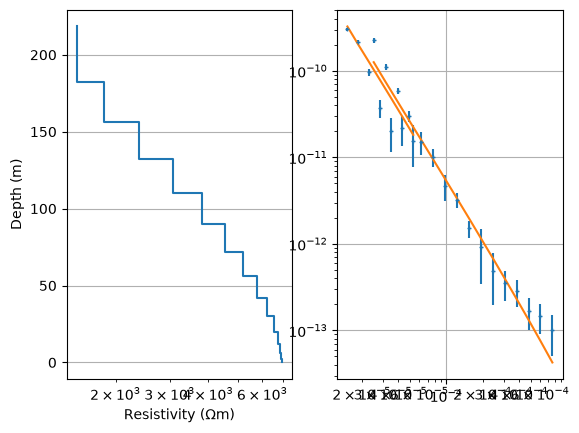

In [11]:
tem.invertSounding(2);

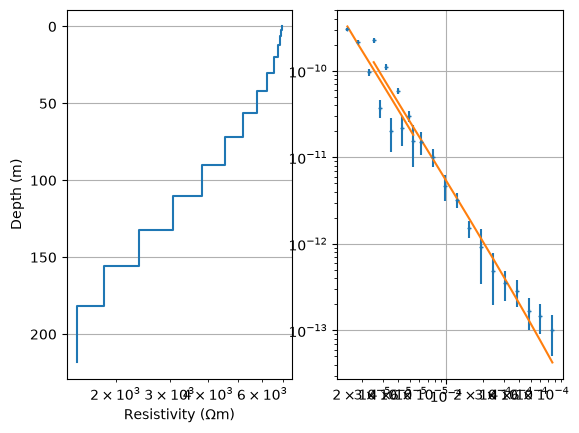

In [13]:
tem.show1dResult();

and see the change from the resistive (>100$\Omega$m) top layer to the conductive layer below (cf. Fig. 4c).
For inverting all soundings subsequently, we use 

22/10/26 - 15:11:31 - pyGIMLi - INFO - Starting inversion.
22/10/26 - 15:11:31 - pyGIMLi - INFO - fop: <pytem.temmodelling.TEMRhoModellingDualMode object at 0x0000025EEA1A66B0>
22/10/26 - 15:11:31 - pyGIMLi - INFO - Data transformation: Arsinh function transformation.
22/10/26 - 15:11:31 - pyGIMLi - INFO - Model transformation: Logarithmic transform
22/10/26 - 15:11:31 - pyGIMLi - INFO - min/max (data): 4.4e-14/2.0e-10
22/10/26 - 15:11:31 - pyGIMLi - INFO - min/max (error): 11.07%/1.0e+10%
22/10/26 - 15:11:31 - pyGIMLi - INFO - min/max (start model): 250/250


--------------------------------------------------------------------------------


22/10/26 - 15:11:51 - pyGIMLi - INFO - inv.iter 0 ... chi² = 69930.31


--------------------------------------------------------------------------------
inv.iter 1 ... 

22/10/26 - 15:11:52 - pyGIMLi - INFO - chi² = 8979.51 (dPhi = 87.14%) lam: 20.0


...

22/10/26 - 15:16:16 - pyGIMLi - INFO - 1: chi2=6.75 (3 iter)
22/10/26 - 15:16:58 - pyGIMLi - INFO - 2: chi2=5.43 (3 iter)
22/10/26 - 15:21:15 - pyGIMLi - INFO - 3: chi2=5.18 (12 iter)
22/10/26 - 15:22:03 - pyGIMLi - INFO - 4: chi2=2.35 (3 iter)
22/10/26 - 15:25:24 - pyGIMLi - INFO - 5: chi2=4.52 (8 iter)
22/10/26 - 15:27:20 - pyGIMLi - INFO - 6: chi2=1.29 (4 iter)
22/10/26 - 15:27:25 - pyGIMLi - INFO - 7: chi2=0.70 (1 iter)


22/10/26 - 15:29:10 - pyGIMLi - INFO - 8: chi2=4.86 (4 iter)
22/10/26 - 15:29:14 - pyGIMLi - INFO - 9: chi2=1.30 (1 iter)


22/10/26 - 15:30:37 - pyGIMLi - INFO - 10: chi2=1.74 (4 iter)
22/10/26 - 15:32:08 - pyGIMLi - INFO - 11: chi2=5.63 (3 iter)
22/10/26 - 15:32:13 - pyGIMLi - INFO - 12: chi2=0.92 (1 iter)


22/10/26 - 15:32:19 - pyGIMLi - INFO - 13: chi2=0.46 (1 iter)


22/10/26 - 15:32:26 - pyGIMLi - INFO - 14: chi2=0.78 (1 iter)


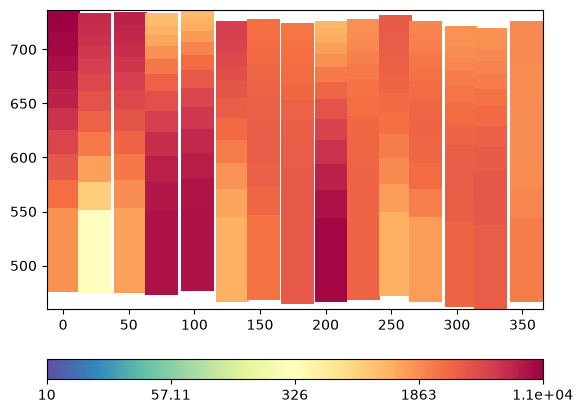

In [14]:
tem.invertAll();

By default, the elevation is extracted and the profile distance is computed by summing the distances.
Adding `usepos='x'`, one can also use Easting or Northing (`usepos='y'`) for display or `usepos=False` for not using any position. You can also specify the color map and color range as known for pyGIMLi plots.

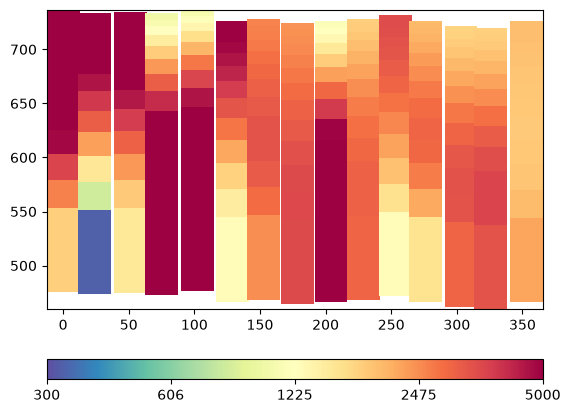

In [20]:
tem.showResults(cMin=300, cMax=5000, cMap="Spectral_r");#, usepos='x');